# Notebook maestro · De JSONLines a la submission
Este notebook ejecuta auditoría → split por familia → variables → SVM OOF → TPE → ensamble → comprobación congelada → refit con todo train → exportación.
**Meta: 95% de accuracy.** El candidato previo obtuvo 94,2095% en selección, 94,2143% en otra partición y **94,428% en Kaggle público**, según el usuario. Los resultados públicos y privados pueden diferir.
El notebook ejecuta todas las etapas de la nueva ronda; el historial de 44 configuraciones se conserva sin obligar a reentrenar cada una. Para la explicación conceptual, abrir `22_caso_desde_cero.ipynb`.

## 1. Entorno y datos
Instalar `requirements_optimized.txt`. En Colab, clonar el repo privado y configurar autenticación fuera del notebook. Los datos se descargan con el helper de Kaggle del repo o se cargan localmente.
Configurar `AP2026Q2_DATA_DIR` con la carpeta que contiene `train_data.jsonlines` y `test_data.jsonlines`. En Windows: `os.environ["AP2026Q2_DATA_DIR"]=r"C:\ruta\datos"`. No incluir tokens en archivos versionados.

In [1]:
get_ipython().run_line_magic('matplotlib','inline')
from pathlib import Path
import os,sys,json
import numpy as np
import pandas as pd
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/competition_pipeline_v2.py').exists()),None)
if ROOT is None:raise RuntimeError('Abrir desde el repo tp_ap.')
sys.path.insert(0,str(ROOT/'src'))
DATA_DIR=Path(os.getenv('AP2026Q2_DATA_DIR',str(ROOT/'data/ap_2026_q_2/raw')))
OUT=Path(os.getenv('AP_OUTPUT_DIR',str(ROOT/'results/round_v2')))
from competition_pipeline_v2 import load_data,groups_for
from optimize_leaderboard import split


## 2. Configuración explícita
`full` ejecuta entrenamientos y exportación. `report` revisa evidencias guardadas sin entrenar.
El train oficial tiene 70.000 filas y el test 30.000. El modo normal falla ante archivos incompletos. El modo parcial es exploratorio y bloquea el refit oficial.
El controlador limita el proceso a 90 minutos. Si se agota el tiempo, conserva resultados parciales y se detiene; no inventa una comprobación ni una submission.

In [2]:
RUN_MODE=os.getenv('AP_RUN_MODE','full')
ALLOW_PARTIAL=os.getenv('AP_ALLOW_PARTIAL','0')=='1'
MINUTES=float(os.getenv('AP_MINUTES','90'))
TRIALS=int(os.getenv('AP_TRIALS','24'))
print({'modo':RUN_MODE,'datos':str(DATA_DIR),'output':str(OUT),'parcial':ALLOW_PARTIAL,'minutos':MINUTES,'ensayos':TRIALS})

{'modo': 'report', 'datos': '/workspace/scratch/d7363d2f086f/data', 'output': '/workspace/scratch/d7363d2f086f/repo/results/round_v2', 'parcial': False, 'minutos': 90.0, 'ensayos': 24}


## 3. Auditoría
Número de filas, JSON válido, etiquetas, hash SHA-256 y ausencia de target en test. No se omiten filas inválidas silenciosamente.
Una primera copia local resultó incompleta durante la sesión; la copia recuperada del ZIP pasó la auditoría con 70.000 y 30.000 filas. La auditoría siguiente, no esa incidencia del entorno, decide qué datos pueden usarse.

In [3]:
train,test,audit=load_data(DATA_DIR,OUT,ALLOW_PARTIAL)
display(pd.DataFrame(audit)[['filename','expected_rows','valid_rows','complete','sha256']])
display(train[['id','title','condition','price','category_id']].head())
print('Train:',train.shape,'Test:',test.shape)

Train: (70000, 45) Test: (30000, 44)


,filename,expected_rows,valid_rows,complete,sha256
0,train_data.jsonlines,70000,70000,True,aa49b8710d06f666eeb3cf65c256c8c4f90bf4dbb22c69...
1,test_data.jsonlines,30000,30000,True,05921bd73deba1c4ed5a4d564e0351729eae8f2ef197bc...


,id,title,condition,price,category_id
0,MLA3911152707,Pizarron 20x30 + Imagen + Bolsita Artesanal- Y...,new,15.02,MLA73721
1,MLA1133955308,Calefactor Tipo Honguito Garrafa 10kg | Tecnja...,new,5520.00,MLA373652
2,MLA3705853907,Remera Manga Larga Talle S Marca Stone Caladit...,used,100.00,MLA119365
3,MLA2969247306,Mimo Remera Manga Larga Talle 4 Años! Oferta!,used,65.00,MLA119482
4,MLA4401281013,Repuesto Pluma Parker Legítima Dorada,new,45.00,MLA3530


## 4. Split por familia y baseline
Cada `parent_item_id` identifica una familia que permanece en un solo lado del split. Si falta, la clave individual incluye el ID de fila. El mismo vendedor puede estar en ambos lados; no evaluamos aquí vendedores totalmente nuevos.
Nueva ronda: 80/20, semilla 42; comprobación: 80/20, semilla 731. El histórico de selección usó 70/30.

In [4]:
y=(train.condition=='used').to_numpy(dtype='int8');groups=groups_for(train)
t,v=split(y,groups,42,2)
assert not set(groups[t])&set(groups[v])
majority=int(y[t].mean()>=.5)
print({'desarrollo':len(t),'validacion':len(v),'familias_compartidas':0,'baseline':float((y[v]==majority).mean())})

{'desarrollo': 56000, 'validacion': 14000, 'familias_compartidas': 0, 'baseline': 0.537}


## 5. Variables y protección contra fuga
| Bloque | Construcción | Dónde aprende |
|---|---|---|
| JSON anidado | Logística, variantes, pagos, fotos, atributos | Parseo fila a fila |
| Atributos | Hasta 250 frecuentes, excluyendo condición explícita | IDs elegidos en desarrollo |
| Texto | Palabras, caracteres, TF-IDF, SVD de 96 componentes | Desarrollo |
| Contexto | Precio relativo y frecuencia por categoría/vendedor | Desarrollo, sin etiquetas |
| Tasas | Vendedor, categoría y combinaciones | OOF interno por familia |
| SVM | Predicciones de texto como otra columna | OOF, con vocabulario refiteado en cada fold |
| Boosting | LightGBM y mezcla de sus configuraciones | Selección y posterior refit |
Las variables describen publicaciones existentes. Cantidades vendidas, estado o fechas posteriores no serían válidos para prometer predicción al crear la publicación. No afirmamos resolver ese escenario temporal distinto.

## 6. Ejecutar el ciclo completo
TPE explora hiperparámetros. Se eligen pesos y umbral en selección; se congelan antes de la comprobación. Ambas particiones proceden del mismo dataset ya explorado: es estabilidad, no un test externo intacto.
Las matrices se reutilizan solo con el mismo hash. Para empezar una ronda nueva desde cero, elegir otra carpeta `OUT`.

In [5]:
import subprocess,time
if RUN_MODE=='full':
    command=[sys.executable,'-u',str(ROOT/'src/competition_pipeline_v2.py'),'--data-dir',str(DATA_DIR),'--output',str(OUT),'--trials',str(TRIALS)]
    if ALLOW_PARTIAL:command+=['--allow-partial','--no-refit']
    log_path=OUT/'master_run.log'
    env=os.environ.copy();env.update(OPENBLAS_NUM_THREADS='4',OMP_NUM_THREADS='4')
    with log_path.open('w') as log:
        process=subprocess.Popen(command,cwd=ROOT,env=env,stdout=log,stderr=subprocess.STDOUT)
        try:returncode=process.wait(timeout=MINUTES*60)
        except subprocess.TimeoutExpired:
            process.terminate()
            try:process.wait(timeout=15)
            except subprocess.TimeoutExpired:process.kill();process.wait()
            raise RuntimeError(f'Presupuesto de {MINUTES} minutos agotado. Resultados parciales en {OUT}.')
    if returncode:raise RuntimeError(log_path.read_text()[-5000:])
    print(log_path.read_text()[-3500:])
elif RUN_MODE=='report':print('Modo reporte: no se entrenaron modelos en esta celda.')
else:raise ValueError('RUN_MODE debe ser full o report')

Modo reporte: no se entrenaron modelos en esta celda.


## 7. Resultados comparables
Accuracy cuenta aciertos; balanced accuracy da igual peso a las clases; macro F1 resume precisión y recall; log loss evalúa probabilidades. El umbral elegido queda asociado al candidato.
Para hablar de avance hacia 95%, el train debe estar completo y la comprobación congelada debe sostenerlo. Un score de selección mayor por sí solo no basta.

Selección todavía pendiente.


,name,accuracy,balanced_accuracy,macro_f1,logloss,threshold,seconds
2,lgb_context_svm_tpe_1,0.939286,0.939972,0.939064,0.155294,0.485,16.569618
7,lgb_context_svm_tpe_6,0.938857,0.938988,0.938575,0.155462,0.540,15.773928
9,lgb_context_svm_tpe_8,0.938500,0.938890,0.938245,0.156154,0.515,9.599591
3,lgb_context_svm_tpe_2,0.938429,0.939323,0.938225,0.157979,0.460,29.090608
1,lgb_context_svm_tpe_0,0.938286,0.938414,0.938001,0.158698,0.540,17.637992
8,lgb_context_svm_tpe_7,0.938071,0.938916,0.937862,0.158259,0.460,15.064497
0,lgb_context_svm_base,0.937571,0.938386,0.937358,0.159605,0.460,20.491973
6,lgb_context_svm_tpe_5,0.937571,0.938333,0.937352,0.160797,0.480,10.264454
5,lgb_context_svm_tpe_4,0.937071,0.937857,0.936853,0.159898,0.475,20.479102
4,lgb_context_svm_tpe_3,0.936643,0.937437,0.936424,0.167803,0.465,10.342269


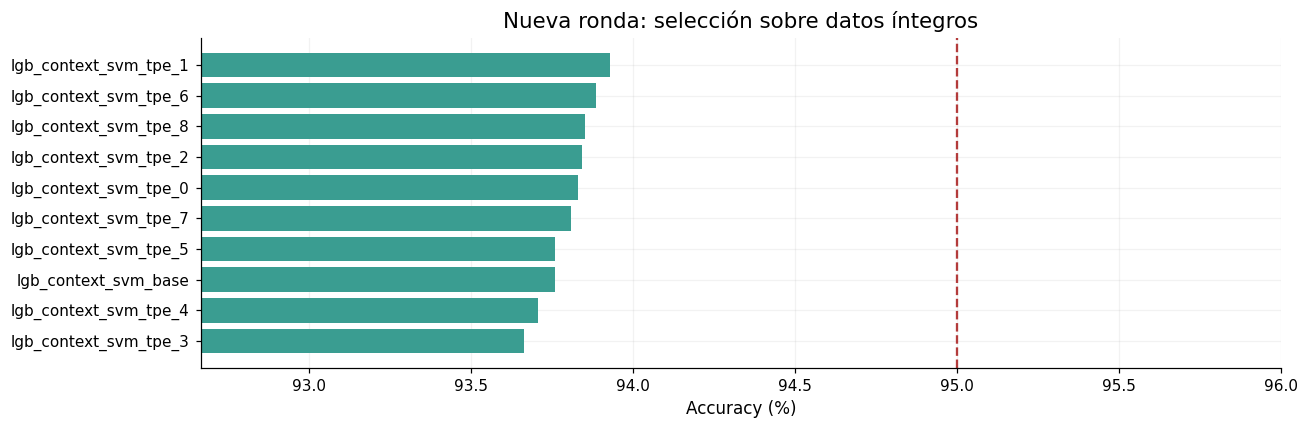

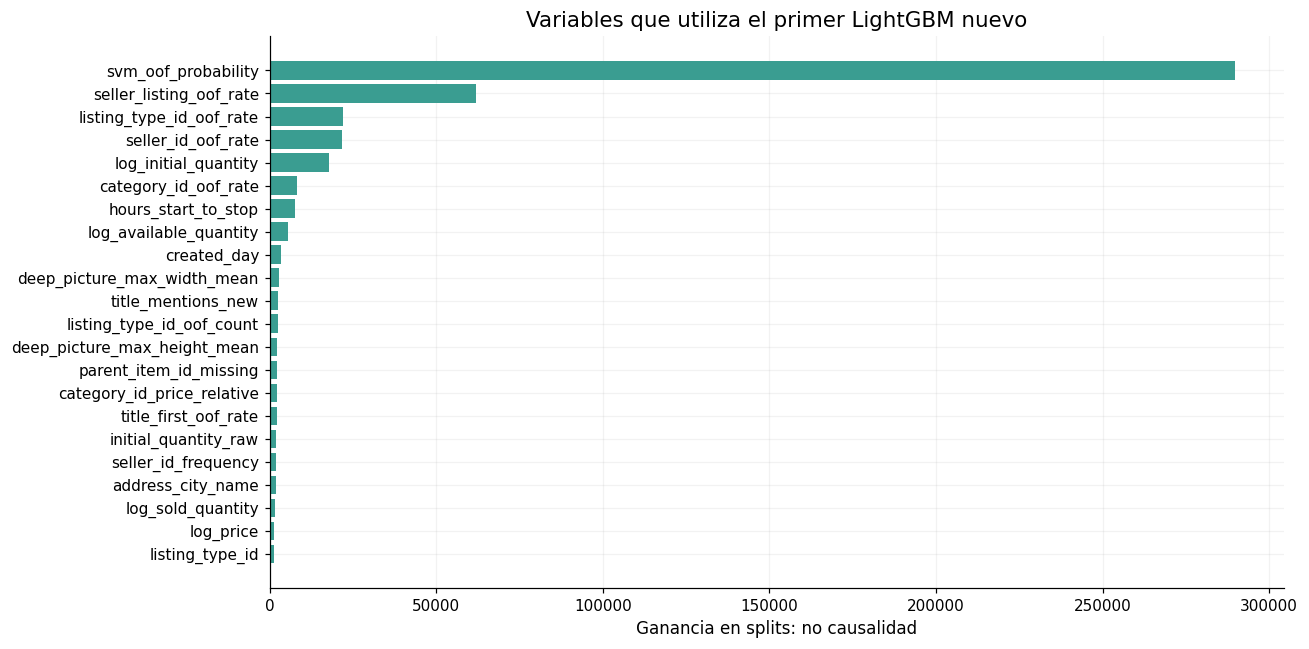

In [6]:
if (OUT/'metrics.csv').exists():display(pd.read_csv(OUT/'metrics.csv').sort_values('accuracy',ascending=False))
if (OUT/'selected.json').exists():
    selected=json.loads((OUT/'selected.json').read_text());display(selected)
    print('Meta local confirmada:',selected['goal_met_local'])
else:print('Selección todavía pendiente.')
from case_visuals import style,new_results,importance
style();new_results(OUT);importance(OUT)

## 8. Submission
Se vuelve a aprender la representación sobre las 70.000 filas y se reentrenan los componentes con los parámetros fijados. Se exportan 30.000 predicciones en el orden del test.
El notebook no envía archivos a Kaggle. La referencia previa permanece en `submissions/submission_optimized_ensemble.csv`. No se la reemplaza automáticamente por una corrida parcial o una mejora sin comprobación.

In [7]:
candidate=OUT/'submission_v2.csv'
if candidate.exists():
    sub=pd.read_csv(candidate)
    assert list(sub.columns)==['ID','condition']
    assert len(sub)==30000 and sub.ID.tolist()==list(range(1,30001))
    assert set(sub.condition)<= {'new','used'} and not sub.isna().any().any()
    display(sub.head());print('Submission nueva:',candidate)
else:print('Sin CSV nuevo todavía. Referencia:',ROOT/'submissions/submission_optimized_ensemble.csv')

Sin CSV nuevo todavía. Referencia: /workspace/scratch/d7363d2f086f/repo/submissions/submission_optimized_ensemble.csv


## 9. Trazabilidad
Se guardan auditoría, hashes, métricas, hiperparámetros efectivos, pesos, umbral, filas de holdout, probabilidades, importancias y submission. Matrices y pesos regenerables quedan fuera de Git.
Para repetir el candidato previo exacto, `src/confirm_and_submit.py` utiliza el ensamble histórico y sus parámetros; puede requerir más tiempo que esta ronda. Para explicar el caso, continuar con el notebook ilustrativo.